In [ ]:
import pandas as pd
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

G = nx.read_graphml('./hs8703_2023.graphml')
N, L = G.number_of_nodes(), G.number_of_edges()
print(f": N = {N}, L = {L}, <k> = {2 * L / N:.2f}")

: N = 193, L = 2140, <k> = 22.18


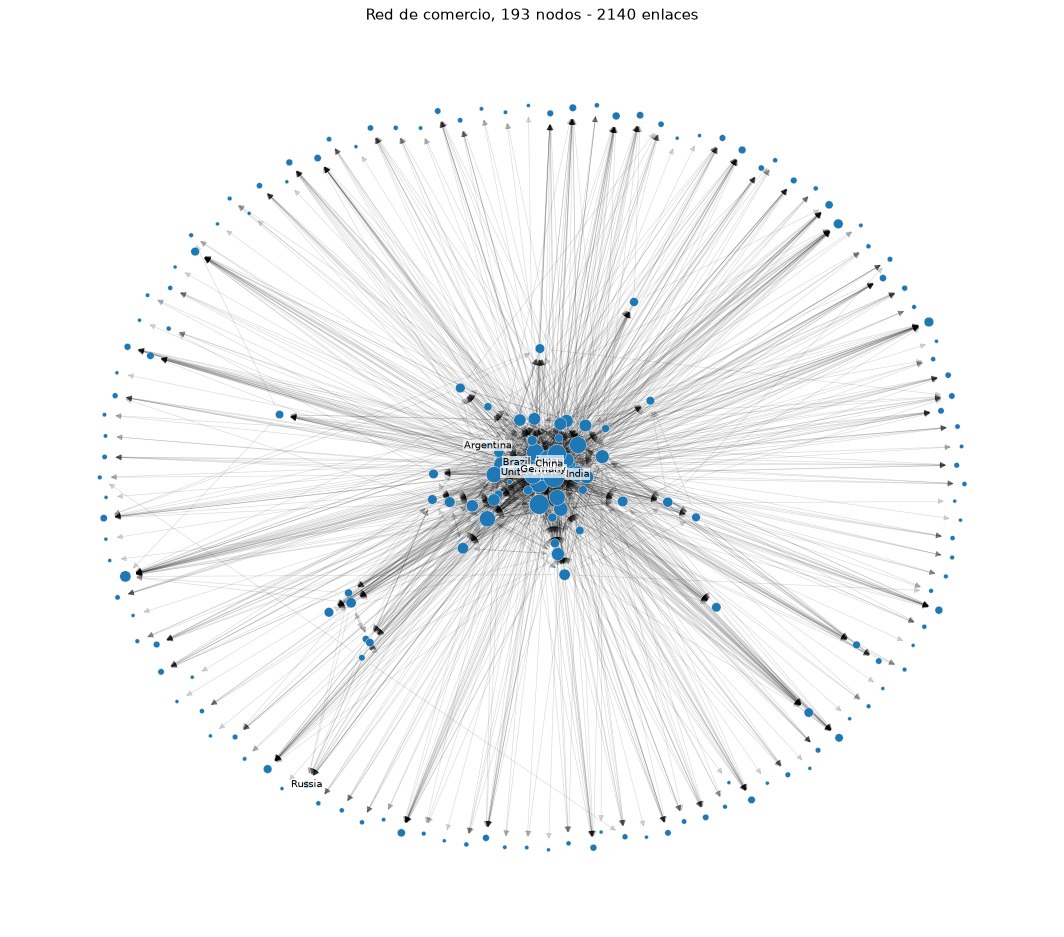

In [463]:
plt.rcParams["figure.dpi"] = 90
pos3 = nx.spring_layout(G, seed=42, weight=None, k=0.3, iterations=200)
PRINCIPALES = {"USA": "United States", "ARG": "Argentina", "BRA": "Brazil",
               "IND": "India", "DEU": "Germany", "JPN": "Japan",
               "CHN": "China", "RUS": "Russia"}

def dibujar(G, pos, color=None, titulo="", cmap="tab10", vmin=None, vmax=None, barra=False):
    """Dibuja la red. color: diccionario nodo -> número (comunidad, core, ...)."""
    fig, ax = plt.subplots(figsize=(15, 13))
    k = dict(G.degree())
    orden = list(G) if color is None else sorted(G, key=color.get)   # los valores altos se dibujan arriba
    c = "tab:blue" if color is None else [color[v] for v in orden]
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.15, width=0.5)
    nodos = nx.draw_networkx_nodes(G, pos, nodelist=orden, ax=ax, node_color=c,
                                   cmap=None if color is None else cmap, vmin=vmin, vmax=vmax,
                                   node_size=[8 + 2 * k[v] for v in orden], edgecolors="white", linewidths=0.3)
    nx.draw_networkx_labels(G, pos, labels={v: n for v, n in PRINCIPALES.items() if v in G}, font_size=8,
                            ax=ax, bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=0.5))
    if barra:
        fig.colorbar(nodos, ax=ax, shrink=0.6)
    ax.set_title(titulo)
    ax.axis("off")
    plt.show()

dibujar(G, pos3, titulo=f"Red de comercio, {N} nodos - {L} enlaces")

## 1. Coeficiente de clustering (#3A)

El clustering local mide qué fracción de los pares de vecinos de un nodo están conectados entre sí (Watts y Strogatz, 1998):

$$C_i = \frac{2\,T_i}{k_i\,(k_i-1)},$$

donde $k_i$ es el grado del nodo $i$ y $T_i$ es la cantidad de enlaces entre sus vecinos, es decir, la cantidad de triángulos que pasan por $i$. El denominador $k_i(k_i-1)/2$ es la cantidad de pares de vecinos. Por lo tanto $C_i = 1$ si todos sus vecinos se conocen y $C_i = 0$ si ninguno se conoce. Si $k_i < 2$ no hay pares, y `networkx` define $C_i = 0$.

Lo calculamos a mano para dos personajes y lo comparamos con `networkx`.

In [472]:
def clustering_a_mano(G, nodo):
    vecinos = list(G.neighbors(nodo))
    k = len(vecinos)
    pares = k * (k - 1) // 2
    T = G.subgraph(vecinos).number_of_edges()   # enlaces entre vecinos = triángulos que pasan por el nodo
    C = T / pares if pares > 0 else 0.0
    print(f"{nodo}: k = {k}, pares de vecinos = {pares}, pares conectados T = {T}")
    print(f"   C a mano = {C:.3f}    networkx = {nx.clustering(G, nodo):.3f}")

clustering_a_mano(G, "IND")
clustering_a_mano(G, "BRA")
print("Vecinos de Hodor:", sorted(G3.neighbors("Bran Stark")))

IND: k = 69, pares de vecinos = 2346, pares conectados T = 446
   C a mano = 0.190    networkx = 0.179
BRA: k = 19, pares de vecinos = 171, pares conectados T = 48
   C a mano = 0.281    networkx = 0.414
Vecinos de Hodor: ['Arya Stark', 'Benjen Stark', 'Catelyn Stark', 'Coldhands', 'Eddard Stark', 'Hodor', 'Joffrey Baratheon', 'Jojen Reed', 'Jon Snow', 'Jon Umber (Greatjon)', 'Meera Reed', 'Nan', 'Rickon Stark', 'Robb Stark', 'Samwell Tarly', 'Sansa Stark', 'Theon Greyjoy']


Tyrion tiene 59 vecinos, es decir 1711 pares posibles, y sólo 243 de esos pares están conectados: $C = 0{,}14$. Tyrion une a gente que no se habla entre sí. Hodor tiene tres vecinos (Bran, Jojen y Meera) que se conocen todos: $C = 1$.

### Dos promedios para toda la red

El clustering medio $\langle C\rangle$ es el promedio de los $C_i$. La transitividad, que usamos en la primera parte, es $3\times$(triángulos)/(tripletes conectados): junta los pares de vecinos de toda la red antes de dividir, y por eso pesan más los nodos de grado alto. El gráfico de $C_i$ contra $k_i$ muestra por qué los dos números son distintos.

Clustering medio <C> = 0.606
Transitividad        = 0.186


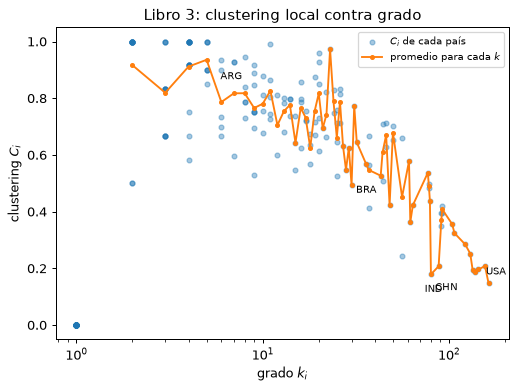

In [475]:
k = dict(G.degree())
C = nx.clustering(G)
print(f"Clustering medio <C> = {nx.average_clustering(G):.3f}")
print(f"Transitividad        = {nx.transitivity(G):.3f}")

# Promedio de C_i para cada valor de k: la curva C(k). Para k < 2 el clustering no está definido.
Ck = pd.DataFrame({"k": k, "C": C}).query("k >= 2").groupby("k")["C"].mean()

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter([k[v] for v in G], [C[v] for v in G], s=15, alpha=0.4, label="$C_i$ de cada país")
ax.plot(Ck.index, Ck.values, "o-", ms=3, color="tab:orange", label="promedio para cada $k$")
for v, (dx, dy) in {"BRA": (-10, 12), "IND": (-5, -14), "ARG": (-40, 14),
                    "CHN": (-30, -16), "USA": (6, -4)}.items():
    ax.annotate(v.split()[0], (k[v], C[v]), fontsize=8, xytext=(dx, dy), textcoords="offset points")
ax.set_xscale("log")
ax.legend(fontsize=8)
ax.set_xlabel("grado $k_i$")
ax.set_ylabel("clustering $C_i$")
ax.set_title("Libro 3: clustering local contra grado")
plt.show()

El clustering baja con el grado. Los personajes con pocos vecinos viven dentro de un solo grupo y tienen $C_i$ cercano a 1. Los de grado alto (Tyrion, Jon, Sansa) unen varios grupos y tienen $C_i$ entre 0,1 y 0,16. Como la transitividad pesa más a estos últimos, da 0,28 contra 0,53 del promedio.

### Para qué sirve: comparar con redes al azar

Un valor de $\langle C\rangle$ solo no dice si es alto o bajo. Lo comparamos con dos redes al azar:

- Erdős–Rényi con los mismos $N$ y $L$. Cada par de nodos está conectado con la misma probabilidad $p = 2L/[N(N-1)]$, independientemente de los demás pares, y entonces $\langle C\rangle \approx p$. Este modelo lo vemos en detalle en la próxima clase.
- Una red con los mismos grados $k_i$, recableada al azar. Es la idea del modelo de configuración de la teórica #3C (acá sin autoenlaces ni enlaces múltiples).

También medimos la distancia media $\langle d\rangle$. Junto con $P(k)$, son las tres métricas centrales de la teórica #3A.

In [486]:
def comparar_con_azar(G, muestras=10):
    N, L = G.number_of_nodes(), G.number_of_edges()
    gigante = lambda H: H.subgraph(max(nx.strongly_connected_components(H), key=len))
    res = {"Erdős–Rényi (mismos N y L)": [], "mismos grados": []}
    for s in range(muestras):
        R = nx.gnm_random_graph(N, L, seed=s, directed=True)
        H = G.copy()
        nx.directed_edge_swap(H, nswap=5 * L, max_tries=100 * L, seed=s)   # recablea sin cambiar ningún k_i
        for nombre, red in [("Erdős–Rényi (mismos N y L)", R), ("mismos grados", H)]:
            res[nombre].append((nx.average_clustering(red), nx.average_shortest_path_length(gigante(red))))
    tabla = {
        "Red": (
            nx.average_clustering(G),
            nx.average_shortest_path_length(gigante(G)),
        )
    }

    tabla.update({nombre: np.mean(v, axis=0) for nombre, v in res.items()})
    return pd.DataFrame(tabla, index=["<C>", "<d>"]).T.round(3)

comparar_con_azar(G)

,<C>,<d>
Red,0.606,1.785
Erdős–Rényi (mismos N y L),0.057,2.447
mismos grados,0.582,1.797


La red de GoT tiene un clustering unas 25 veces mayor que la de Erdős–Rényi y unas 4 veces mayor que la red con los mismos grados, mientras que la distancia media es parecida (3,4 contra 3,2 y 3,0). Las redes al azar tienen caminos igual de cortos, pero casi no tienen triángulos.

Los triángulos aparecen porque los amigos de mis amigos suelen ser mis amigos, es decir, porque hay grupos cohesivos. Una red al azar no los tiene (hipótesis H3 de #3C). Ésta es la primera señal de que la red tiene comunidades, y es lo que buscamos en el resto del notebook.

## 2. Cliques (#3B)

Una clique es un conjunto de nodos donde todos están conectados con todos. Es maximal si no se le puede agregar ningún nodo sin romper esa propiedad. `nx.find_cliques` lista todas las cliques maximales (algoritmo de Bron–Kerbosch). Las cliques se pueden superponer: un nodo puede estar en muchas.

In [487]:
cliques = list(nx.find_cliques(G))
tamanos = Counter(len(q) for q in cliques)
print(f"Cliques maximales: {len(cliques)}. La más grande tiene {max(tamanos)} nodos.")

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.bar(list(tamanos.keys()), list(tamanos.values()))
ax.set_xlabel("tamaño de la clique maximal")
ax.set_ylabel("cantidad")
ax.set_title("Libro 3")
plt.show()

mayor = max(cliques, key=len)
print("La clique más grande:", ", ".join(sorted(mayor)))

NetworkXNotImplemented: not implemented for directed type

La clique más grande tiene 11 personajes y no es un grupo que se reúne: es la lista de nombres que Arya repite cada noche antes de dormir (Joffrey, Cersei, Ilyn Payne, Meryn Trant, Sandor y Gregor Clegane, Dunsen, Polliver, Rafford y Tickler), más la propia Arya. Como los enlaces se definen por nombres que aparecen cerca en el texto, la lista queda conectada de a pares. Es un efecto de cómo se construyó la red. Antes de interpretar una estructura conviene mirar qué hay detrás.

Las cliques se superponen: un personaje puede estar en muchas.

In [7]:
# En cuántas cliques maximales está cada personaje
pertenencia = Counter(v for q in cliques for v in q)
print("Personajes en más cliques maximales:")
for v, n in pertenencia.most_common(5):
    print(f"   {v:20s} {n:3d} cliques   (k = {G3.degree(v)})")

Personajes en más cliques maximales:
   Tyrion Lannister      92 cliques   (k = 59)
   Joffrey Baratheon     65 cliques   (k = 50)
   Robb Stark            63 cliques   (k = 49)
   Jon Snow              63 cliques   (k = 52)
   Jaime Lannister       61 cliques   (k = 45)


Tyrion está en 92 cliques maximales: no pertenece a un grupo, pertenece a muchos que se superponen.

### La clique es frágil

Para ser una clique tienen que estar todos los enlaces. Lo probamos con la lista de Arya: sacamos un solo enlace, el de Arya con Tickler, y buscamos de nuevo las cliques entre esos 11 personajes.

In [8]:
H = G3.subgraph(mayor).copy()          # los 11 de la lista y los enlaces entre ellos
H.remove_edge("Arya Stark", "Tickler")
print(f"Enlaces entre los 11: {H.number_of_edges()} de {11 * 10 // 2} posibles")
print("Cliques maximales entre los 11:")
for q in nx.find_cliques(H):
    print(f"   {len(q)} personajes (queda afuera: {', '.join(set(mayor) - set(q))})")
print("Cada uno de los 11 tiene al menos", min(k for _, k in H.degree()), "vecinos dentro del grupo")

Enlaces entre los 11: 54 de 55 posibles
Cliques maximales entre los 11:
   10 personajes (queda afuera: Tickler)
   10 personajes (queda afuera: Arya Stark)
Cada uno de los 11 tiene al menos 9 vecinos dentro del grupo


Con 54 de los 55 enlaces, el grupo ya no es una clique: se parte en dos cliques de 10, una sin Arya y otra sin Tickler. Sin embargo, cada personaje sigue conectado con al menos 9 de los otros 10, y el grupo sigue siendo igual de cohesivo. Por eso la clique es una definición de grupo demasiado estricta (#3B). Pedir que cada nodo tenga al menos $k$ vecinos dentro del grupo es más tolerante: es la idea del k-core.

## 3. k-core (#3B)

El k-core es el subgrafo más grande en el que todos los nodos tienen al menos $k$ vecinos dentro del subgrafo (Seidman, 1983). Es una idea parecida a la clique, pero menos estricta. Se calcula podando: se sacan los nodos de grado menor que $k$, eso baja el grado de sus vecinos, y se repite hasta que no quede nadie para sacar. El número de core de un nodo es el mayor $k$ para el cual el nodo está en el k-core.

In [34]:
%%time 
def k_core_a_mano(G, k):
    H = G.copy()
    while True:
        chicos = [v for v, grado in H.degree() if grado < k]
        if not chicos:
            return H
        H.remove_nodes_from(chicos)

print(" k   nodos (a mano)   nodos (networkx)")
for k in range(1, 12):
    print(f"{k:2d}   {k_core_a_mano(G3, k).number_of_nodes():10d}   {nx.k_core(G3, k).number_of_nodes():14d}")

 k   nodos (a mano)   nodos (networkx)
 1          303              303
 2          245              245
 3          179              179
 4          141              141
 5           97               97
 6           82               82
 7           48               48
 8           24               24
 9           11               11
10           11               11
11            0                0
CPU times: user 37.3 ms, sys: 3.8 ms, total: 41.1 ms
Wall time: 40.6 ms


Cantidad de nodos por número de core: {1: 58, 2: 66, 3: 38, 4: 44, 5: 15, 6: 34, 7: 24, 8: 13, 10: 11}
El 10-core: Arya Stark, Cersei Lannister, Dunsen, Gregor Clegane, Ilyn Payne, Joffrey Baratheon, Meryn Trant, Polliver, Rafford, Sandor Clegane, Tickler


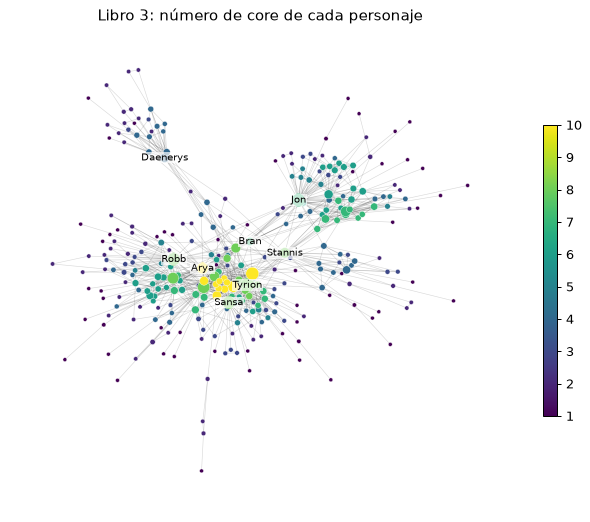

CPU times: user 83.5 ms, sys: 9.75 ms, total: 93.2 ms
Wall time: 94.7 ms


In [37]:
%%time 
core = nx.core_number(G3)
kmax = max(core.values())
print("Cantidad de nodos por número de core:", dict(sorted(Counter(core.values()).items())))
print(f"El {kmax}-core:", ", ".join(sorted(v for v in G3 if core[v] == kmax)))
dibujar(G3, pos3, color=core, cmap="viridis", barra=True, titulo="Libro 3: número de core de cada personaje")

Las capas forman una cebolla: los personajes con un solo enlace quedan en el borde y el centro es denso. El core más alto es el 10-core, con 11 personajes: otra vez la lista de Arya. No es casualidad, porque una clique de $n$ nodos es un $(n-1)$-core. El 8-core ya tiene 24 personajes, casi todos de Desembarco del Rey y de la guerra en las Tierras de los Ríos.

El k-core encuentra un centro, no grupos separados. Para separar tramas necesitamos otra idea: comunidades.

## 4. Comunidades: cortar los puentes (Girvan–Newman, #3C)

Una comunidad es un conjunto de nodos con muchos enlaces adentro y pocos hacia afuera. Para encontrarlas, Girvan y Newman (2002) usan la betweenness de los enlaces.

**Betweenness de un enlace.** En la clase 2 vimos la betweenness de un nodo: cuántos de los caminos más cortos entre otros nodos pasan por él. La de un enlace se define igual, contando los caminos más cortos que usan ese enlace:

$$x_{ij} = \sum_{s<t} \frac{\sigma_{st}(i,j)}{\sigma_{st}},$$

donde la suma recorre todos los pares de nodos $s,t$, $\sigma_{st}$ es la cantidad de caminos más cortos entre $s$ y $t$, y $\sigma_{st}(i,j)$ es cuántos de ellos pasan por el enlace $(i,j)$. Si entre $s$ y $t$ hay un solo camino más corto, el par suma 1 a cada enlace de ese camino. `networkx` divide por la cantidad de pares, $N(N-1)/2$, así que el resultado es la fracción de pares que se comunican por ese enlace.

Lo vemos en una red chica: dos grupos de 4 nodos, todos conectados entre sí, unidos por un solo enlace.

In [11]:
B = nx.barbell_graph(4, 0)      # grupos {0, 1, 2, 3} y {4, 5, 6, 7}, unidos por el enlace 3–4
xB = nx.edge_betweenness_centrality(B)
for (i, j), donde in [((3, 4), "el puente"), ((0, 3), "adentro, tocando el puente"), ((0, 1), "adentro, lejos del puente")]:
    print(f"   enlace {i}–{j} ({donde}): x = {xB[(i, j)]:.3f}")
print("Pares de nodos:", 8 * 7 // 2)

   enlace 3–4 (el puente): x = 0.571
   enlace 0–3 (adentro, tocando el puente): x = 0.179
   enlace 0–1 (adentro, lejos del puente): x = 0.036
Pares de nodos: 28


Hay 28 pares de nodos. El puente lo usan los $4 \times 4 = 16$ pares que tienen un nodo de cada lado: $16/28 = 0{,}57$. El enlace 0–3 lo usan el par (0, 3) y los cuatro pares que van de 0 al otro grupo: $5/28 = 0{,}18$. El enlace 0–1 sólo lo usa el par (0, 1): $1/28 = 0{,}04$. Los enlaces entre comunidades son los de betweenness alta.

El algoritmo de Girvan–Newman saca el enlace de mayor betweenness, recalcula la betweenness de todos los enlaces y repite. La red se va partiendo en componentes. Ahora en el libro 3.

In [12]:
eb = nx.edge_betweenness_centrality(G3)
print("Enlaces con mayor betweenness:")
for (u, v), b in sorted(eb.items(), key=lambda x: -x[1])[:5]:
    print(f"   {u} – {v}: {b:.3f}")

primer_corte = next(nx.community.girvan_newman(G3))     # primera partición en dos componentes
chica = min(primer_corte, key=len)
print(f"\nPrimer corte: {sorted(len(c) for c in primer_corte)} personajes")
print("Personajes del grupo chico con mayor grado:", ", ".join(sorted(chica, key=G3.degree, reverse=True)[:6]))

Enlaces con mayor betweenness:
   Daenerys Targaryen – Robert Baratheon: 0.108
   Robb Stark – Jon Snow: 0.050
   Jon Snow – Robert Baratheon: 0.043
   Tyrion Lannister – Jeor Mormont: 0.039
   Joffrey Baratheon – Jon Snow: 0.035

Primer corte: [27, 276] personajes
Personajes del grupo chico con mayor grado: Daenerys Targaryen, Jorah Mormont, Arstan, Daario Naharis, Belwas, Jhiqui


El enlace con más betweenness une a Daenerys con Robert Baratheon, a quien ella recuerda como el Usurpador: es el puente entre Essos y Poniente. Su valor, 0,11, dice que cerca del 11 % de los pares de personajes se comunican por ese enlace. El primer corte separa los 27 personajes de la trama de Daenerys.

Girvan–Newman da una jerarquía de cortes pero no dice dónde parar, y es caro: cada recálculo de betweenness cuesta $O(NL)$ y hay que hacerlo después de cada corte. Para decidir qué partición es buena necesitamos una medida: la modularidad.

## 5. Modularidad (#3C)

Una partición es buena si hay más enlaces dentro de las comunidades que los que habría por azar. El azar es el modelo de configuración: cada enlace se corta en dos mitades y las mitades se reconectan al azar, respetando el grado de cada nodo. La cantidad de enlaces esperada entre $v$ y $w$ es $k_v k_w/2L$. La modularidad suma, sobre los pares de una misma comunidad, la diferencia entre lo real y lo esperado (Newman y Girvan, 2004):

$$Q = \frac{1}{2L}\sum_{v,w}\left[A_{vw} - \frac{k_v k_w}{2L}\right]\delta(c_v,c_w) = \sum_{c}\left[\frac{L_c}{L} - \left(\frac{K_c}{2L}\right)^2\right],$$

donde $L_c$ es la cantidad de enlaces dentro de la comunidad $c$ y $K_c$ es la suma de los grados de sus nodos. La segunda forma es la que programamos. Primero miramos dos pares de nodos.

In [13]:
L3 = G3.number_of_edges()
for v, w in [("Jon Snow", "Ygritte"), ("Jon Snow", "Cersei Lannister")]:
    esperado = G3.degree(v) * G3.degree(w) / (2 * L3)
    print(f"{v} – {w}: A = {int(G3.has_edge(v, w))}, esperado por azar = {esperado:.2f}")

Jon Snow – Ygritte: A = 1, esperado por azar = 0.26
Jon Snow – Cersei Lannister: A = 0, esperado por azar = 0.98


Jon e Ygritte tienen un enlace donde el azar esperaría 0,26: si están en la misma comunidad, suman a $Q$. Jon y Cersei no tienen enlace donde el azar esperaría casi uno: ponerlos juntos resta.

Ahora programamos $Q$ y lo probamos con tres particiones: todos en una sola comunidad, ocho grupos al azar, y una partición por casas (cada personaje con apellido de una casa grande va a esa casa, el resto queda solo).

In [14]:
def modularidad(G, comunidades):
    L = G.number_of_edges()
    Q = 0.0
    for c in comunidades:
        L_c = G.subgraph(c).number_of_edges()        # enlaces dentro de c
        K_c = sum(k for _, k in G.degree(c))         # suma de grados de c
        Q += L_c / L - (K_c / (2 * L)) ** 2
    return Q

nodos = list(G3)
rng = np.random.default_rng(0)
grupo = rng.integers(0, 8, len(nodos))
al_azar = [{v for v, g in zip(nodos, grupo) if g == i} for i in range(8)]

CASAS = {"Stark", "Lannister", "Baratheon", "Targaryen", "Tyrell", "Martell", "Greyjoy",
         "Frey", "Tully", "Arryn", "Mormont", "Bolton", "Florent", "Westerling", "Clegane"}
def casa(v):
    apellido = v.split(" (")[0].split()[-1]
    return apellido if apellido in CASAS else v      # sin casa: queda solo
por_casa = {}
for v in nodos:
    por_casa.setdefault(casa(v), set()).add(v)
por_casa = list(por_casa.values())

for nombre, P in [("todos juntos", [set(nodos)]), ("8 grupos al azar", al_azar), ("por casa", por_casa)]:
    print(f"{nombre:18s} Q a mano = {modularidad(G3, P):6.3f}   networkx = {nx.community.modularity(G3, P, weight=None):6.3f}")

todos juntos       Q a mano =  0.000   networkx =  0.000
8 grupos al azar   Q a mano = -0.012   networkx = -0.012
por casa           Q a mano =  0.062   networkx =  0.062


Todos juntos da $Q = 0$ exactamente: dentro de una sola comunidad lo real y lo esperado suman lo mismo. Ocho grupos al azar dan $Q \approx 0$. Agrupar por casa da $Q = 0{,}06$: las familias no son comunidades en esta red, porque los Stark y los Lannister están repartidos por todo el mapa. Buscamos ahora la partición que maximiza $Q$.

## 6. Algoritmo de Louvain (#3C)

Probar todas las particiones es imposible. Louvain (Blondel et al., 2008) arma la partición de a pasos: en cada paso hace el cambio que más aumenta $Q$ en ese momento, sin volver atrás. Por eso no garantiza encontrar el máximo de $Q$, pero en la práctica llega cerca. Tiene dos fases:

1. Cada nodo empieza en su propia comunidad. Para cada nodo se calcula cuánto cambia $Q$ si se lo mueve a la comunidad de cada vecino, y se lo mueve a la que da el mayor aumento. Se repite hasta que ningún movimiento aumenta $Q$.
2. Cada comunidad se convierte en un supernodo (sus enlaces internos quedan como autoenlaces) y se vuelve a la fase 1 con esta red más chica.

Las dos fases se repiten hasta que $Q$ deja de crecer, y cada pasada da un nivel de meta-comunidades. Es rápido: en el trabajo original se aplicó a una red de 2,6 millones de clientes de telefonía celular en Bélgica, donde aparecen las comunidades de habla francesa y neerlandesa (la última slide de #3C). Los nodos se recorren en orden aleatorio, así que fijamos la semilla.

8 comunidades.  Q a mano = 0.616   networkx = 0.616
Enlaces entre comunidades distintas: 19 %

0:  77 personajes   Tyrion Lannister, Joffrey Baratheon, Sansa Stark, Jaime Lannister
1:  67 personajes   Jon Snow, Samwell Tarly, Mance Rayder, Maester Aemon
2:  52 personajes   Robb Stark, Catelyn Stark, Roose Bolton, Brienne of Tarth
3:  39 personajes   Robert Baratheon, Daenerys Targaryen, Jorah Mormont, Aerys II Targaryen
4:  27 personajes   Arya Stark, Gregor Clegane, Sandor Clegane, Lem
5:  22 personajes   Stannis Baratheon, Davos Seaworth, Melisandre, Axell Florent
6:  15 personajes   Bran Stark, Eddard Stark, Gilly, Rickon Stark
7:   4 personajes   Robett Glover, Helman Tallhart, Randyll Tarly, Galbart Glover


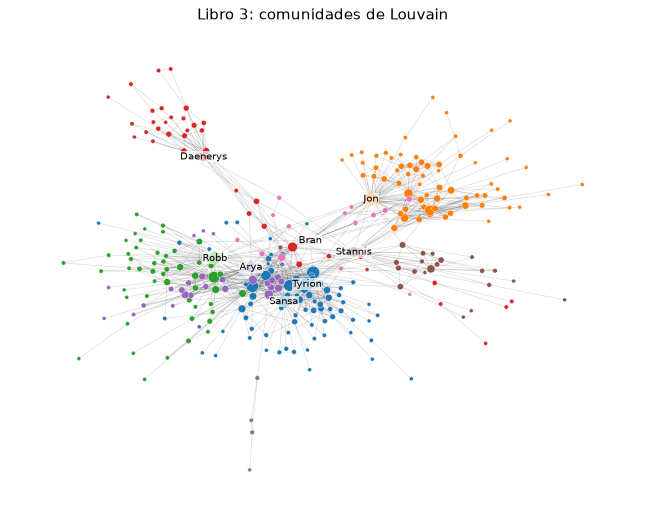

In [447]:
def listar_comunidades(G, comunidades, n=4):
    for i, c in enumerate(comunidades):
        top = sorted(c, key=G.degree, reverse=True)[:n]
        print(f"{i}: {len(c):3d} personajes   {', '.join(top)}")

def fraccion_entre(G, comunidades):
    etiqueta = {v: i for i, c in enumerate(comunidades) for v in c}
    return sum(etiqueta[u] != etiqueta[v] for u, v in G.edges()) / G.number_of_edges()

com3 = sorted(nx.community.louvain_communities(G3, weight=None, seed=43), key=len, reverse=True)
print(f"{len(com3)} comunidades.  Q a mano = {modularidad(G3, com3):.3f}   "
      f"networkx = {nx.community.modularity(G3, com3, weight=None):.3f}")
print(f"Enlaces entre comunidades distintas: {100 * fraccion_entre(G3, com3):.0f} %\n")
listar_comunidades(G3, com3)

etiqueta3 = {v: i for i, c in enumerate(com3) for v in c}
dibujar(G3, pos3, color=etiqueta3, vmin=0, vmax=9, titulo="Libro 3: comunidades de Louvain")

Las comunidades son tramas y lugares, no familias: Desembarco del Rey alrededor de Tyrion, Joffrey, Sansa y Cersei; la guerra en las Tierras de los Ríos con Robb, Catelyn, Jaime y Tywin; el Muro con Jon, Sam y Mance; Essos con Daenerys y Jorah; Rocadragón con Stannis, Davos y Melisandre; la Hermandad sin Estandartes; el viaje de Bran. Con esta semilla aparece también una comunidad chica con Tallhart y los Glover, la misma cadena que estaba en un extremo del vector de Fiedler en la clase 2. Menos de un enlace de cada cinco une comunidades distintas (en la red de blogs políticos de #3B era el 15 %).

### Meta-comunidades

`louvain_partitions` devuelve la partición al final de cada pasada.

In [444]:
for nivel, P in enumerate(nx.community.louvain_partitions(G3, weight=None)):
    print(f"pasada {nivel + 1}: {len(P):3d} comunidades, Q = {nx.community.modularity(G3, P, weight=None):.3f}")

pasada 1:  35 comunidades, Q = 0.551
pasada 2:  10 comunidades, Q = 0.608


La primera pasada junta a los 303 personajes en unas cuarenta comunidades chicas. Las siguientes juntan esas comunidades en meta-comunidades, hasta que $Q$ deja de crecer.

### Robustez: semillas, resolución y pesos

Probamos otras semillas, la resolución $\gamma$ y los pesos. La resolución multiplica el término del azar, $Q_\gamma = \sum_c [L_c/L - \gamma\,(K_c/2L)^2]$: con $\gamma > 1$ salen comunidades más chicas y con $\gamma < 1$ más grandes. En la tabla, $Q$ siempre se evalúa con $\gamma = 1$.

In [446]:
filas = []
for semilla in range(42):
    P = nx.community.louvain_communities(G3, weight=None, seed=semilla)
    filas.append(("no", 1.0, semilla, len(P), nx.community.modularity(G3, P, weight=None)))
for gamma in [0.5, 2.0]:
    P = nx.community.louvain_communities(G3, weight=None, resolution=gamma, seed=42)
    filas.append(("no", gamma, 42, len(P), nx.community.modularity(G3, P, weight=None)))
P = nx.community.louvain_communities(G3, weight="weight", seed=42)
filas.append(("sí", 1.0, 42, len(P), nx.community.modularity(G3, P, weight="weight")))

pd.DataFrame(filas, columns=["pesos", "resolución γ", "semilla", "comunidades", "Q"]).round(3)

,pesos,resolución γ,semilla,comunidades,Q
0,no,1.0,0,8,0.618
1,no,1.0,1,8,0.605
2,no,1.0,2,9,0.590
3,no,1.0,3,7,0.612
4,no,1.0,4,8,0.620
5,no,1.0,5,7,0.608
6,no,1.0,6,9,0.604
7,no,1.0,7,9,0.616
8,no,1.0,8,8,0.606
9,no,1.0,9,8,0.616


Con distintas semillas $Q$ cambia en la segunda decimal, pero la cantidad de comunidades cambia: hay muchas particiones con $Q$ casi máximo y Louvain encuentra una de ellas (Good, de Montjoye y Clauset, 2010). La resolución cambia el tamaño de las comunidades, y no hay un tamaño correcto. Además, la modularidad no puede ver comunidades por debajo de cierto tamaño, que depende de $L$ (límite de resolución, Fortunato y Barthélemy, 2007). Con pesos, tomando el peso como fuerza del vínculo, $Q$ es mayor: los enlaces fuertes están adentro de las comunidades.

## 7. Libro 3 contra libro 5

Juntamos todo en una tabla para los dos libros.

In [18]:
def resumen(G, semilla=42):
    N, L = G.number_of_nodes(), G.number_of_edges()
    com = nx.community.louvain_communities(G, weight=None, seed=semilla)
    return {"N": N, "L": L, "<k>": 2 * L / N,
            "<C>": nx.average_clustering(G),
            "clique máx.": max(len(q) for q in nx.find_cliques(G)),
            "k-core máx.": max(nx.core_number(G).values()),
            "comunidades": len(com),
            "Q": nx.community.modularity(G, com, weight=None),
            "% enlaces entre com.": 100 * fraccion_entre(G, com)}

pd.DataFrame([resumen(G3), resumen(G5)], index=["Libro 3", "Libro 5"]).round(2)

,N,L,<k>,<C>,clique máx.,k-core máx.,comunidades,Q,% enlaces entre com.
Libro 3,303,1008,6.65,0.53,11,10,8,0.61,17.86
Libro 5,317,760,4.79,0.49,7,6,7,0.69,13.55


In [19]:
com5 = sorted(nx.community.louvain_communities(G5, weight=None, seed=42), key=len, reverse=True)
print("Comunidades del libro 5:\n")
listar_comunidades(G5, com5)
core5 = nx.core_number(G5)
print(f"\nEl {max(core5.values())}-core del libro 5:",
      ", ".join(sorted(v for v in G5 if core5[v] == max(core5.values()))))

Comunidades del libro 5:

0:  66 personajes   Jon Snow, Melisandre, Selyse Florent, Bowen Marsh
1:  59 personajes   Daenerys Targaryen, Barristan Selmy, Hizdahr zo Loraq, Quentyn Martell
2:  54 personajes   Cersei Lannister, Doran Martell, Robert Baratheon, Jaime Lannister
3:  52 personajes   Theon Greyjoy, Ramsay Snow, Mance Rayder, Wyman Manderly
4:  41 personajes   Stannis Baratheon, Asha Greyjoy, Davos Seaworth, Godry Farring
5:  35 personajes   Tyrion Lannister, Connington, Aegon Targaryen (son of Rhaegar), Haldon
6:  10 personajes   Victarion Greyjoy, Moqorro, Euron Greyjoy, Aeron Greyjoy

El 6-core del libro 5: Aegon Targaryen (son of Rhaegar), Barristan Selmy, Connington, Daario Naharis, Daenerys Targaryen, Grey Worm, Haldon, Hizdahr zo Loraq, Irri, Jhiqui, Lemore, Missandei, Rolly Duckfield, Skahaz mo Kandaq, Tyrion Lannister, Yandry, Ysilla


En el libro 5 las tramas están más separadas: Daenerys en Meereen, Jon en el Muro, Tyrion viajando por Essos, Theon y Ramsay en el Norte, los hijos del hierro por su cuenta. Con semilla 42, la modularidad sube de 0,61 a 0,69 y la fracción de enlaces entre comunidades baja de 18 % a 14 %. La red también es menos densa ($\langle k\rangle = 4{,}79$ contra $6{,}65$) y el centro es más chico: el k-core máximo es el 6-core, con 17 personajes que son la corte de Daenerys en Meereen y el barco en el que viaja Tyrion con Aegon (el joven Griff).

## Posibles continuaciones

Ideas para seguir explorando después de la clase.

1. **Club de karate.** `nx.karate_club_graph()` es la red de Zachary (1977) de la teórica #3B. El atributo `club` de cada nodo dice con quién se fue cada socio después de la pelea. Corran Louvain y Girvan–Newman y comparen con la división real. ¿Cuántos socios quedan mal asignados?
2. **Girvan–Newman con modularidad.** Recorran los niveles de `nx.community.girvan_newman(G5)` (los primeros 15 alcanzan) y calculen $Q$ en cada uno. ¿En qué nivel es máximo? ¿Cómo se compara con Louvain?
3. **Pesos.** Comparen las comunidades del libro 3 con `weight=None` y con `weight="weight"`. ¿Qué personajes cambian de comunidad y por qué?
4. **Clustering y comunidades.** Calculen $\langle C\rangle$ del subgrafo de cada comunidad de Louvain y compárenlo con el de una red al azar con los mismos $N$ y $L$ que ese subgrafo.
5. **Formación de opiniones (#3B).** Asignen a cada personaje una opinión $+1$ o $-1$ al azar. En cada paso, elijan un nodo al azar y denle la opinión de la mayoría de sus vecinos. ¿Se llega a una sola opinión, o sobreviven opiniones distintas en comunidades distintas?

## Resumen

- El clustering mide qué fracción de mis vecinos se conocen entre sí. En el libro 3 es unas 25 veces mayor que en una red al azar con los mismos $N$ y $L$: hay grupos cohesivos.
- La clique es la definición más estricta de grupo y es frágil. La más grande del libro 3 es un efecto de cómo se armó la red.
- El k-core encuentra el centro denso de la red, no sus grupos.
- La modularidad compara los enlaces internos de una partición con los que daría el modelo de configuración. Louvain la maximiza y encuentra las tramas del libro: las comunidades son lugares e historias, no familias.

## Referencias

- D. J. Watts y S. H. Strogatz, Nature 393, 440 (1998): coeficiente de clustering.
- W. W. Zachary, J. Anthropol. Res. 33, 452 (1977): club de karate.
- S. B. Seidman, Social Networks 5, 269 (1983): k-cores.
- M. Girvan y M. E. J. Newman, PNAS 99, 7821 (2002): comunidades por betweenness de enlaces.
- M. E. J. Newman y M. Girvan, Phys. Rev. E 69, 026113 (2004): modularidad.
- V. D. Blondel, J.-L. Guillaume, R. Lambiotte y E. Lefebvre, J. Stat. Mech. P10008 (2008): algoritmo de Louvain.
- S. Fortunato y M. Barthélemy, PNAS 104, 36 (2007): límite de resolución.
- B. H. Good, Y.-A. de Montjoye y A. Clauset, Phys. Rev. E 81, 046106 (2010): muchas particiones con modularidad casi máxima.
- S. Fortunato, Phys. Rep. 486, 75 (2010): revisión de detección de comunidades.
- A.-L. Barabási, *Network Science* (Cambridge University Press, 2016), cap. 9: comunidades. Libre en networksciencebook.com.
- A. Beveridge y J. Shan, Math Horizons 23(4), 18 (2016): *Network of Thrones*. Datos en github.com/mathbeveridge/asoiaf.